# Lab 4
Датасет: `Loan_approval_data_2025.csv`.

## Шаг 0. Импорты и загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler, RobustScaler

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)

URL = "https://storage.yandexcloud.net/lms-itmo-ru-files-27a87tyf/AI%20Culture/DA/lesson04/en/Loan_approval_data_2025.csv"
loan = pd.read_csv(URL)
print(loan.shape)
loan.head()

(50000, 20)


,customer_id,age,occupation_status,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,product_type,loan_intent,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,loan_status
0,CUST100000,40,Employed,17.2,25579,692,5.3,895,10820,0,0,0,Credit Card,Business,600,17.02,0.423,0.023,0.008,1
1,CUST100001,33,Employed,7.3,43087,627,3.5,169,16550,0,1,0,Personal Loan,Home Improvement,53300,14.10,0.384,1.237,0.412,0
2,CUST100002,42,Student,1.1,20840,689,8.4,17,7852,0,0,0,Credit Card,Debt Consolidation,2100,18.33,0.377,0.101,0.034,1
3,CUST100003,53,Student,0.5,29147,692,9.8,1480,11603,0,1,0,Credit Card,Business,2900,18.74,0.398,0.099,0.033,1
4,CUST100004,32,Employed,12.5,63657,630,7.2,209,12424,0,0,0,Personal Loan,Education,99600,13.92,0.195,1.565,0.522,1


## Шаг 1. что за столбцы
Смотрим типы, пропуски, дубликаты и число уникальных значений.

In [2]:
audit = pd.DataFrame({
    "dtype": loan.dtypes.astype(str),
    "missing": loan.isna().sum(),
    "n_unique": loan.nunique(),
    "example": loan.iloc[0],
})
display(audit)
print("Дубликатов строк:", loan.duplicated().sum())

,dtype,missing,n_unique,example
customer_id,str,0,50000,CUST100000
age,int64,0,53,40
occupation_status,str,0,3,Employed
years_employed,float64,0,395,17.2
annual_income,int64,0,35770,25579
credit_score,int64,0,432,692
credit_history_years,float64,0,301,5.3
savings_assets,int64,0,10382,895
current_debt,int64,0,25350,10820
defaults_on_file,int64,0,2,0


Дубликатов строк: 0


## Шаг 2. Роли столбцов
- **служебный**: `customer_id` (уникален в каждой строке, модели он не нужен, поэтому исключаем);
- **целевая переменная**: `loan_status` (0/1, не преобразуем);
- **категориальные**: `occupation_status` (3 значения), `product_type` (3), `loan_intent` (6);
- **бинарный признак**: `defaults_on_file` (0/1);
- **числовые**: все остальные.

In [3]:
TARGET      = "loan_status"
SERVICE     = ["customer_id"]
CATEGORICAL = ["occupation_status", "product_type", "loan_intent"]
BINARY      = ["defaults_on_file"]
NUMERIC     = [c for c in loan.columns if c not in SERVICE + CATEGORICAL + BINARY + [TARGET]]
print("Числовые:", NUMERIC)

Числовые: ['age', 'years_employed', 'annual_income', 'credit_score', 'credit_history_years', 'savings_assets', 'current_debt', 'delinquencies_last_2yrs', 'derogatory_marks', 'loan_amount', 'interest_rate', 'debt_to_income_ratio', 'loan_to_income_ratio', 'payment_to_income_ratio']


## Шаг 3. Приведение типов
1) текстовые категории → `category`,
2) бинарные → `int8`,
3) счётчики и суммы → `int64`,
4) непрерывные → `float64`.

In [4]:
X = loan.drop(columns=SERVICE + [TARGET]).copy()
y = loan[TARGET].astype("int8")

for c in CATEGORICAL:
    X[c] = X[c].astype("category")
X["defaults_on_file"] = X["defaults_on_file"].astype("int8")

INT_COLS = ["age", "credit_score", "delinquencies_last_2yrs", "derogatory_marks",
            "annual_income", "savings_assets", "current_debt", "loan_amount"]
FLOAT_COLS = ["years_employed", "credit_history_years", "interest_rate",
              "debt_to_income_ratio", "loan_to_income_ratio", "payment_to_income_ratio"]
X[INT_COLS]   = X[INT_COLS].astype("int64")
X[FLOAT_COLS] = X[FLOAT_COLS].astype("float64")
X.dtypes

age                           int64
occupation_status          category
years_employed              float64
annual_income                 int64
credit_score                  int64
credit_history_years        float64
savings_assets                int64
current_debt                  int64
defaults_on_file               int8
delinquencies_last_2yrs       int64
derogatory_marks              int64
product_type               category
loan_intent                category
loan_amount                   int64
interest_rate               float64
debt_to_income_ratio        float64
loan_to_income_ratio        float64
payment_to_income_ratio     float64
dtype: object

## Шаг 4. Кодирование категорий

Label Encoding не используем, т.к. у всех трёх признаков нет естественного порядка, числа 0, 1, 2 создали бы ложное сравнение.

Frequency Encoding не нужен, такю как он полезен, когда категорий много и One-Hot раздувает таблицу, а здесь это не так. Возможно можно было бы его использовать с loan_intent, но мне кажется что 6 значений еще терпимо.

In [5]:
X_ohe = pd.get_dummies(X[CATEGORICAL], dtype=int)
print("One-Hot столбцов:", X_ohe.shape[1])
X_ohe.head()

One-Hot столбцов: 12


,occupation_status_Employed,occupation_status_Self-Employed,occupation_status_Student,product_type_Credit Card,product_type_Line of Credit,product_type_Personal Loan,loan_intent_Business,loan_intent_Debt Consolidation,loan_intent_Education,loan_intent_Home Improvement,loan_intent_Medical,loan_intent_Personal
0,1,0,0,1,0,0,1,0,0,0,0,0
1,1,0,0,0,0,1,0,0,0,1,0,0
2,0,0,1,1,0,0,0,1,0,0,0,0
3,0,0,1,1,0,0,1,0,0,0,0,0
4,1,0,0,0,0,1,0,0,1,0,0,0


## Шаг 5. Асимметрия: нужен ли логарифм
Правило: логарифмируем **непрерывные** признаки, у которых **skew больше 1** (правый хвост) и логарифм делает распределение симметричнее.

Счётные признаки с несколькими целыми значениями и большой долей нулей (`derogatory_marks`, `delinquencies_last_2yrs`) логарифмировать не будем, так как логарифм не меняет число разных значений и не растаскивает нули, поэтому форма гистограммы остаётся ступенчатой.

Среднее заметно больше медианы означает правый хвост.
Используем `ln(x+1)` (`np.log1p`), потому что в `savings_assets` и `years_employed` есть нули, а `ln(0)` не определён. Отрицательных значений нет, поэтому версия `ln(x - min(x) + 1)` не нужна.

In [6]:
check = pd.DataFrame({
    "mean": X[NUMERIC].mean(),
    "median": X[NUMERIC].median(),
    "skew": X[NUMERIC].skew(),
    "skew_after_log1p": np.log1p(X[NUMERIC]).skew(),
    "min": X[NUMERIC].min(),
}).round(2).sort_values("skew", ascending=False)
display(check)

,mean,median,skew,skew_after_log1p,min
savings_assets,3595.62,568.00,12.05,-0.25,0.00
derogatory_marks,0.15,0.00,3.12,2.51,0.00
current_debt,14290.44,10385.00,2.44,-0.45,60.00
annual_income,50062.89,41607.50,1.89,0.19,15000.00
delinquencies_last_2yrs,0.55,0.00,1.82,0.95,0.00
years_employed,7.45,4.90,1.29,-0.10,0.00
credit_history_years,8.17,6.10,0.95,-0.23,0.00
loan_amount,33041.87,26100.00,0.93,-0.88,500.00
payment_to_income_ratio,0.23,0.21,0.66,0.43,0.00
loan_to_income_ratio,0.70,0.62,0.66,0.18,0.01


Кандидаты на логарифм: ['years_employed', 'annual_income', 'savings_assets', 'current_debt']


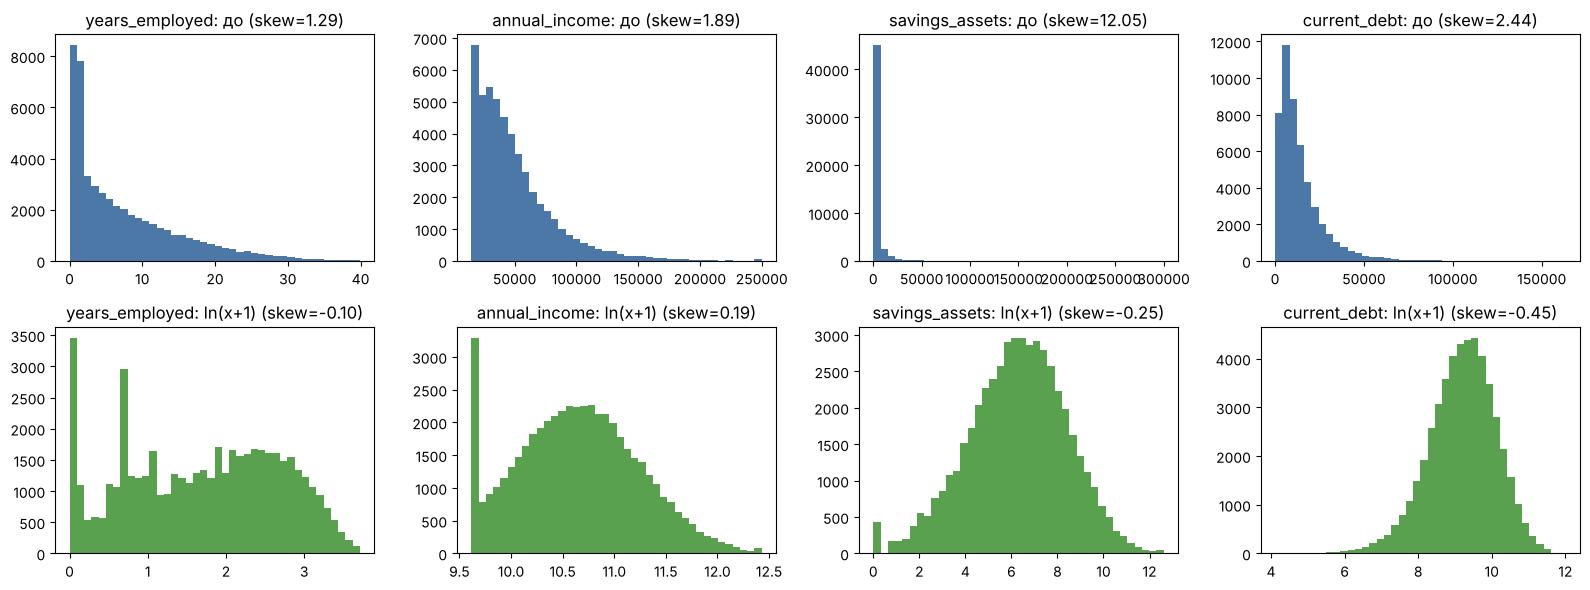

In [7]:
# Гистограммы признаков с сильной асимметрией: до и после ln(x+1)
COUNTS = ["derogatory_marks", "delinquencies_last_2yrs"]   # счётчики: целые 0, 1, 2, ...
skewed = [c for c in NUMERIC if X[c].skew() > 1 and c not in COUNTS]   # непрерывные с skew > 1
print("Кандидаты на логарифм:", skewed)
fig, ax = plt.subplots(2, len(skewed), figsize=(4 * len(skewed), 6))
for i, c in enumerate(skewed):
    ax[0, i].hist(X[c], bins=40, color="#4c78a8"); ax[0, i].set_title(f"{c}: до (skew={X[c].skew():.2f})")
    l = np.log1p(X[c])
    ax[1, i].hist(l, bins=40, color="#59a14f");    ax[1, i].set_title(f"{c}: ln(x+1) (skew={l.skew():.2f})")
plt.tight_layout(); plt.show()

**Решение.** Логарифмируем четыре непрерывных признака с skew > 1: `savings_assets`, `current_debt`, `annual_income`, `years_employed`.

После `ln(x+1)` skew у всех ближе к нулю (от −0.45 до 0.19).

**Счётчики не логарифмируем.**

## Шаг 5б. Выбросы: чем масштабировать
Чтобы выбрать между RobustScaler и StandardScaler, смотрим, сколько в каждом признаке выбросов по правилу **1.5 × IQR** :
- IQR = Q3 − Q1, где Q1 и Q3 это 25-й и 75-й процентили;
- выброс: значение ниже `Q1 − 1.5 × IQR` или выше `Q3 + 1.5 × IQR`.


In [8]:
def outlier_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

outliers = pd.DataFrame({
    "выбросы_до_лога_%": [outlier_share(X[c]) for c in NUMERIC],
    "выбросы_после_ln(x+1)_%": [outlier_share(np.log1p(X[c])) for c in NUMERIC],
    "IQR": [X[c].quantile(0.75) - X[c].quantile(0.25) for c in NUMERIC],
}, index=NUMERIC).round(1).sort_values("выбросы_до_лога_%", ascending=False)
display(outliers)

,выбросы_до_лога_%,выбросы_после_ln(x+1)_%,IQR
savings_assets,13.0,1.0,2141.0
derogatory_marks,12.8,12.8,0.0
current_debt,5.9,1.3,12868.2
annual_income,4.7,0.2,35442.8
delinquencies_last_2yrs,3.5,0.2,1.0
years_employed,2.7,0.0,10.1
credit_score,0.7,1.0,87.0
credit_history_years,0.7,0.0,10.6
debt_to_income_ratio,0.7,0.0,0.2
age,0.2,0.0,17.0


**Вывод.** Заметные выбросы до логарифма только у четырёх признаков, которые мы логарифмируем.

У остальных непрерывных признаков выбросов почти нет.

Поэтому логика такая: признаки с выбросами идут через логарифм и RobustScaler, остальные через StandardScaler.

После логарифма выбросов в этих четырёх признаках остаётся уже мало, так что разница между двумя скейлерами небольшая.

RobustScaler выбран для них как для самых грязных признаков, оба варианта допустимы.

## Шаг 6. Масштабирование
- прологарифмированные признаки используем **RobustScaler** (медиана и IQR, устойчив к оставшимся выбросам);
- остальные числовые признаки используем **StandardScaler** (mean 0, std 1).
- бинарный `defaults_on_file`, one-hot столбцы, счетчики ("derogatory_marks", "delinquencies_last_2yrs") и цель **не масштабируем**.

In [9]:
# Логарифм ln(x+1) и RobustScaler для непрерывных признаков с skew > 1
LOG_ROBUST = ["annual_income", "savings_assets", "current_debt", "years_employed"]
assert set(LOG_ROBUST) == set(skewed), "список логарифмируемых не совпал с правилом"
X_log = pd.DataFrame(RobustScaler().fit_transform(np.log1p(X[LOG_ROBUST])),
                     columns=[c + "_log_robust" for c in LOG_ROBUST], index=X.index)

# StandardScaler для остальных
STD_COLS = ["age", "credit_score", "credit_history_years", "interest_rate", "loan_amount",
            "debt_to_income_ratio", "loan_to_income_ratio", "payment_to_income_ratio"]
X_std = pd.DataFrame(StandardScaler().fit_transform(X[STD_COLS]),
                     columns=[c + "_std" for c in STD_COLS], index=X.index)

display(pd.concat([X_log, X_std], axis=1).describe().T[["mean", "std", "min", "max"]].round(2))

,mean,std,min,max
annual_income_log_robust,0.01,0.71,-1.23,2.15
savings_assets_log_robust,-0.03,0.75,-2.22,2.20
current_debt_log_robust,-0.05,0.77,-4.30,2.30
years_employed_log_robust,-0.05,0.59,-1.05,1.15
age_std,0.00,1.00,-1.53,3.15
credit_score_std,-0.00,1.00,-4.57,3.19
credit_history_years_std,-0.00,1.00,-1.13,3.03
interest_rate_std,-0.00,1.00,-2.34,1.84
loan_amount_std,-0.00,1.00,-1.25,2.56
debt_to_income_ratio_std,-0.00,1.00,-1.78,3.22


## Шаг 7. Сборка итогового CSV и проверки

In [10]:
COUNTS = ["derogatory_marks", "delinquencies_last_2yrs"]   # счётчики, остаются как есть (без log и scaler)

machine_ready = pd.concat([X[["defaults_on_file"]], X_ohe, X_log, X_std, X[COUNTS], y], axis=1)

assert machine_ready.isna().sum().sum() == 0, "есть пропуски"
assert all(pd.api.types.is_numeric_dtype(t) for t in machine_ready.dtypes), "остались нечисловые столбцы"
assert "customer_id" not in machine_ready.columns, "id попал в признаки"
assert machine_ready.shape == (50000, 28), "ожидали 28 столбцов"
print("Размер:", machine_ready.shape)

machine_ready.to_csv("loan_approval_machine_ready.csv", index=False)
print("Сохранён: loan_approval_machine_ready.csv")
machine_ready.head()

Размер: (50000, 28)


Сохранён: loan_approval_machine_ready.csv


,defaults_on_file,occupation_status_Employed,occupation_status_Self-Employed,occupation_status_Student,product_type_Credit Card,product_type_Line of Credit,product_type_Personal Loan,loan_intent_Business,loan_intent_Debt Consolidation,loan_intent_Education,loan_intent_Home Improvement,loan_intent_Medical,loan_intent_Personal,annual_income_log_robust,savings_assets_log_robust,current_debt_log_robust,years_employed_log_robust,age_std,credit_score_std,credit_history_years_std,interest_rate_std,loan_amount_std,debt_to_income_ratio_std,loan_to_income_ratio_std,payment_to_income_ratio_std,derogatory_marks,delinquencies_last_2yrs,loan_status
0,0,1,0,0,1,0,0,1,0,0,0,0,0,-0.584349,0.159140,0.034319,0.668612,0.453563,0.747482,-0.397958,0.374003,-1.242226,0.859129,-1.457758,-1.455529,0,0,1
1,0,1,0,0,0,0,1,0,0,0,1,0,0,0.041968,-0.423410,0.389775,0.202579,-0.176018,-0.256675,-0.647698,-0.343811,0.775700,0.615051,1.148607,1.146448,0,1,0
2,0,0,0,1,1,0,0,0,1,0,0,0,0,-0.830450,-1.210391,-0.233840,-0.613143,0.633444,0.701137,0.032151,0.696037,-1.184790,0.571242,-1.290298,-1.288075,0,0,1
3,0,0,0,1,1,0,0,1,0,0,0,0,0,-0.427509,0.335268,0.092755,-0.812855,1.622787,0.747482,0.226393,0.796826,-1.154157,0.702669,-1.294592,-1.294515,0,1,1
4,0,1,0,0,0,0,1,0,0,1,0,0,0,0.510751,-0.349350,0.149935,0.491301,-0.265959,-0.210330,-0.134343,-0.388060,2.548565,-0.567789,1.852798,1.854907,0,0,1
